In [401]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "nanuag_mitarbeiter_G05_V01.csv",
    sep=";"
)

df.head()

,Personalnummer,Anrede,Vorname,Nachname,Geburtsdatum,Abteilung,Standort,Jahresgehalt,Fuehrungsposition
0,100000,Frau,Karin,Wolf,09.11.1959,Personal,Rostock,51723.0700,Nein
1,100001,Frau,Claudia,Müller,01.03.1985,Produktion,Bremen,40237.3700,Nein
2,100002,Frau,Ute,Schmitt,12.11.1977,Finanzen,Dortmund,52036.6000,Nein
3,100003,Herr,Kevin,Schmitt,08.05.1981,Produktion,Bremen,48732.8900,Nein
4,100004,Herr,Christian,Lang,18.06.1994,Logistik,Dortmund,44368.7000,Nein


In [402]:
print(df.shape)
df.info()

(100000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Personalnummer     100000 non-null  int64  
 1   Anrede             100000 non-null  str    
 2   Vorname            100000 non-null  str    
 3   Nachname           100000 non-null  str    
 4   Geburtsdatum       100000 non-null  str    
 5   Abteilung          100000 non-null  str    
 6   Standort           100000 non-null  str    
 7   Jahresgehalt       100000 non-null  float64
 8   Fuehrungsposition  100000 non-null  str    
dtypes: float64(1), int64(1), str(7)
memory usage: 6.9 MB


In [403]:

df.isna().sum()

Personalnummer       0
Anrede               0
Vorname              0
Nachname             0
Geburtsdatum         0
Abteilung            0
Standort             0
Jahresgehalt         0
Fuehrungsposition    0
dtype: int64

In [404]:

df["Geburtsdatum"] = pd.to_datetime(
    df["Geburtsdatum"],
    format="%d.%m.%Y",
    errors="coerce"
)

print("Ungültige Geburtsdaten:", df["Geburtsdatum"].isna().sum())
df = df.dropna(subset=["Geburtsdatum"])
df.info()


Ungültige Geburtsdaten: 858
<class 'pandas.DataFrame'>
Index: 99142 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Personalnummer     99142 non-null  int64         
 1   Anrede             99142 non-null  str           
 2   Vorname            99142 non-null  str           
 3   Nachname           99142 non-null  str           
 4   Geburtsdatum       99142 non-null  datetime64[us]
 5   Abteilung          99142 non-null  str           
 6   Standort           99142 non-null  str           
 7   Jahresgehalt       99142 non-null  float64       
 8   Fuehrungsposition  99142 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 7.6 MB


In [405]:

today = pd.Timestamp.now()
future_dates = df["Geburtsdatum"] > today

print("Zukünftige Geburtsdaten:", future_dates.sum())

df=df.loc[~future_dates]

df.info()


Zukünftige Geburtsdaten: 286
<class 'pandas.DataFrame'>
Index: 98856 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Personalnummer     98856 non-null  int64         
 1   Anrede             98856 non-null  str           
 2   Vorname            98856 non-null  str           
 3   Nachname           98856 non-null  str           
 4   Geburtsdatum       98856 non-null  datetime64[us]
 5   Abteilung          98856 non-null  str           
 6   Standort           98856 non-null  str           
 7   Jahresgehalt       98856 non-null  float64       
 8   Fuehrungsposition  98856 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 7.5 MB


In [406]:

duplicates = df.duplicated(subset="Personalnummer")

print("Doppelte Personalnummern:", duplicates.sum())

df = df.drop_duplicates(
    subset="Personalnummer",
    keep="first"
)

df.info()


Doppelte Personalnummern: 284
<class 'pandas.DataFrame'>
Index: 98572 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Personalnummer     98572 non-null  int64         
 1   Anrede             98572 non-null  str           
 2   Vorname            98572 non-null  str           
 3   Nachname           98572 non-null  str           
 4   Geburtsdatum       98572 non-null  datetime64[us]
 5   Abteilung          98572 non-null  str           
 6   Standort           98572 non-null  str           
 7   Jahresgehalt       98572 non-null  float64       
 8   Fuehrungsposition  98572 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 7.5 MB


In [407]:

df["Jahresgehalt"].describe()

count    98572.0000
mean     50391.4229
std      29909.9040
min         -1.0000
25%      42748.4500
50%      49039.3850
75%      55549.5475
max     999999.9900
Name: Jahresgehalt, dtype: float64

In [408]:

invalid_salary = (
    (df["Jahresgehalt"] <= 0) |
    (df["Jahresgehalt"] > 900000)
)

print("Unplausible Gehälter:", invalid_salary.sum())

df=df.loc[~invalid_salary]

df.info()



Unplausible Gehälter: 285
<class 'pandas.DataFrame'>
Index: 98287 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Personalnummer     98287 non-null  int64         
 1   Anrede             98287 non-null  str           
 2   Vorname            98287 non-null  str           
 3   Nachname           98287 non-null  str           
 4   Geburtsdatum       98287 non-null  datetime64[us]
 5   Abteilung          98287 non-null  str           
 6   Standort           98287 non-null  str           
 7   Jahresgehalt       98287 non-null  float64       
 8   Fuehrungsposition  98287 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 7.5 MB


In [409]:

suspicious_names = ~df["Nachname"].str.fullmatch(
    r"[A-ZÄÖÜ][a-zäöüß]{2,}",
    na=False
)

print("Verdächtige Nachnamen:", suspicious_names.sum())

df.loc[suspicious_names, "Nachname"] = pd.NA

df.info()

Verdächtige Nachnamen: 286
<class 'pandas.DataFrame'>
Index: 98287 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Personalnummer     98287 non-null  int64         
 1   Anrede             98287 non-null  str           
 2   Vorname            98287 non-null  str           
 3   Nachname           98001 non-null  str           
 4   Geburtsdatum       98287 non-null  datetime64[us]
 5   Abteilung          98287 non-null  str           
 6   Standort           98287 non-null  str           
 7   Jahresgehalt       98287 non-null  float64       
 8   Fuehrungsposition  98287 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 7.5 MB


In [410]:

q1 = df["Jahresgehalt"].quantile(0.25)
q3 = df["Jahresgehalt"].quantile(0.75)

iqr = q3 - q1

untergrenze = q1 - 1.5 * iqr
obergrenze = q3 + 1.5 * iqr

ausreisser = (
    (df["Jahresgehalt"] < untergrenze) |
    (df["Jahresgehalt"] > obergrenze)
)

print(f"Untergrenze: {untergrenze:.2f} €")
print(f"Obergrenze: {obergrenze:.2f} €")
print("Anzahl Ausreißer:", ausreisser.sum())

Untergrenze: 23648.71 €
Obergrenze: 74682.73 €
Anzahl Ausreißer: 438


In [411]:

gehalt_vorher = df["Jahresgehalt"].copy()

df["Jahresgehalt"] = df["Jahresgehalt"].clip(
    lower=untergrenze,
    upper=obergrenze
)

df.info()


<class 'pandas.DataFrame'>
Index: 98287 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Personalnummer     98287 non-null  int64         
 1   Anrede             98287 non-null  str           
 2   Vorname            98287 non-null  str           
 3   Nachname           98001 non-null  str           
 4   Geburtsdatum       98287 non-null  datetime64[us]
 5   Abteilung          98287 non-null  str           
 6   Standort           98287 non-null  str           
 7   Jahresgehalt       98287 non-null  float64       
 8   Fuehrungsposition  98287 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 7.5 MB


In [412]:
valid_anrede = ["Herr", "Frau", "Divers"]

invalid_anrede = ~df["Anrede"].isin(valid_anrede)

print("Ungültige Anreden:", invalid_anrede.sum())

Ungültige Anreden: 0


In [413]:

bereinigung = pd.DataFrame({
    "Fehlerart": [
        "Fehlende Werte (ursprünglich)",
        "Ungültige Geburtsdaten",
        "Zukünftige Geburtsdaten",
        "Doppelte Personalnummern",
        "Unplausible Gehälter",
        "Ungültige Nachnamen",
        "Gehaltsausreißer (IQR)",
        "Ungültige Anrede-Werte"
    ],
    "Anzahl": [0, 858, 286, 284, 285, 286, 438, 0],
    "Maßnahme": [
        "Keine",
        "Zeilen entfernt",
        "Zeilen entfernt",
        "Weitere Einträge entfernt (keep=first)",
        "Zeilen entfernt",
        "Durch NaN ersetzt",
        "Werte auf IQR-Grenzen begrenzt",
        "Keine"
    ]
})

display(bereinigung)

,Fehlerart,Anzahl,Maßnahme
0,Fehlende Werte (ursprünglich),0,Keine
1,Ungültige Geburtsdaten,858,Zeilen entfernt
2,Zukünftige Geburtsdaten,286,Zeilen entfernt
3,Doppelte Personalnummern,284,Weitere Einträge entfernt (keep=first)
4,Unplausible Gehälter,285,Zeilen entfernt
5,Ungültige Nachnamen,286,Durch NaN ersetzt
6,Gehaltsausreißer (IQR),438,Werte auf IQR-Grenzen begrenzt
7,Ungültige Anrede-Werte,0,Keine


## Datenbereinigung – Vorgehensweise

Die Personaldaten wurden anhand festgelegter Regeln systematisch bereinigt:

<li>Datensätze mit ungültigen oder zukünftigen Geburtsdaten wurden entfernt.</li>
<li>Datensätze mit unplausiblen Gehaltsangaben wurden anhand festgelegter Plausibilitätsgrenzen entfernt.</li>
<li>Bei mehrfach vorkommenden Personalnummern wurde jeweils der erste Datensatz beibehalten.

<li>Offensichtlich fehlerhafte Nachnamen wurden durch fehlende Werte ersetzt, da die übrigen Informationen weiterhin für die statistische Analyse verwendet werden können.</li>

<li>Zur Behandlung der Gehaltsausreißer wurde das IQR-Kriterium mit dem Faktor 1,5 angewendet. Die identifizierten Gehaltsausreißer wurden auf die berechneten IQR-Grenzen begrenzt (Winsorization), um den Einfluss extremer Werte zu reduzieren und gleichzeitig die Datensätze zu erhalten.</li>
</ul>

Nach der Bereinigung verbleiben **98.287 Datensätze**.

In [414]:
stichtag = pd.Timestamp("2026-12-31")
df["Alter"] = stichtag.year - df["Geburtsdatum"].dt.year
df[["Geburtsdatum", "Alter"]].head()

,Geburtsdatum,Alter
0,1959-11-09,67
1,1985-03-01,41
2,1977-11-12,49
3,1981-05-08,45
4,1994-06-18,32


In [415]:
df["Anrede"].value_counts()

Anrede
Herr      47809
Frau      47593
Divers     2885
Name: count, dtype: int64

In [416]:


df["Altersklasse"] = pd.cut(
   df["Alter"],
    bins=[-np.inf, 20, 30, 40, 50, np.inf],
    labels=["≤20", "21-30", "31-40", "41-50", ">50"]
)

table = pd.crosstab(df["Altersklasse"], df["Anrede"])

print(table)

Anrede        Divers   Frau   Herr
Altersklasse                      
≤20               60    962   1013
21-30            553   9762   9713
31-40            600   9763   9811
41-50            600   9586   9652
>50             1072  17520  17620


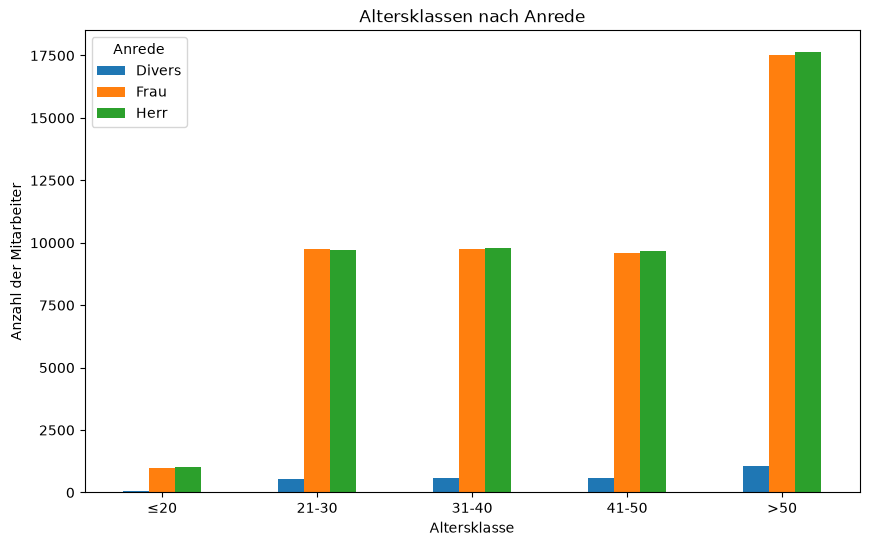

In [417]:
table.plot(kind="bar", figsize=(10, 6))

plt.title("Altersklassen nach Anrede")
plt.xlabel("Altersklasse")
plt.ylabel("Anzahl der Mitarbeiter")
plt.xticks(rotation=0)

plt.show()

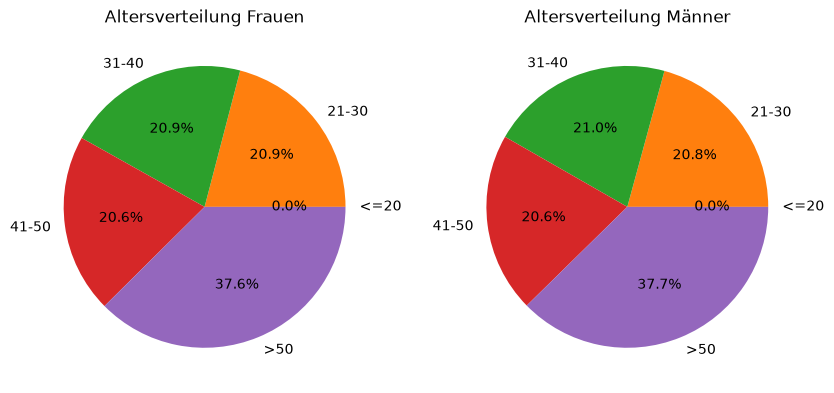

In [418]:
frau = df[df["Anrede"] == "Frau"]
herr = df[df["Anrede"] == "Herr"]

order = ["<=20", "21-30", "31-40", "41-50", ">50"]

frau_counts = frau["Altersklasse"].value_counts().reindex(order, fill_value=0)
herr_counts = herr["Altersklasse"].value_counts().reindex(order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].pie(frau_counts, labels=frau_counts.index, autopct="%1.1f%%")
axes[0].set_title("Altersverteilung Frauen")

axes[1].pie(herr_counts, labels=herr_counts.index, autopct="%1.1f%%")
axes[1].set_title("Altersverteilung Männer")

plt.show()

Anrede                   Divers   Frau   Herr
Abteilung                                    
Finanzen                    225   3861   3838
Forschung & Entwicklung     237   3792   4281
IT                          284   4321   4615
Kundenservice               278   4729   4347
Logistik                    321   5637   5676
Personal                    209   3355   2873
Produktion                  850  14330  14521
Vertrieb                    481   7568   7658


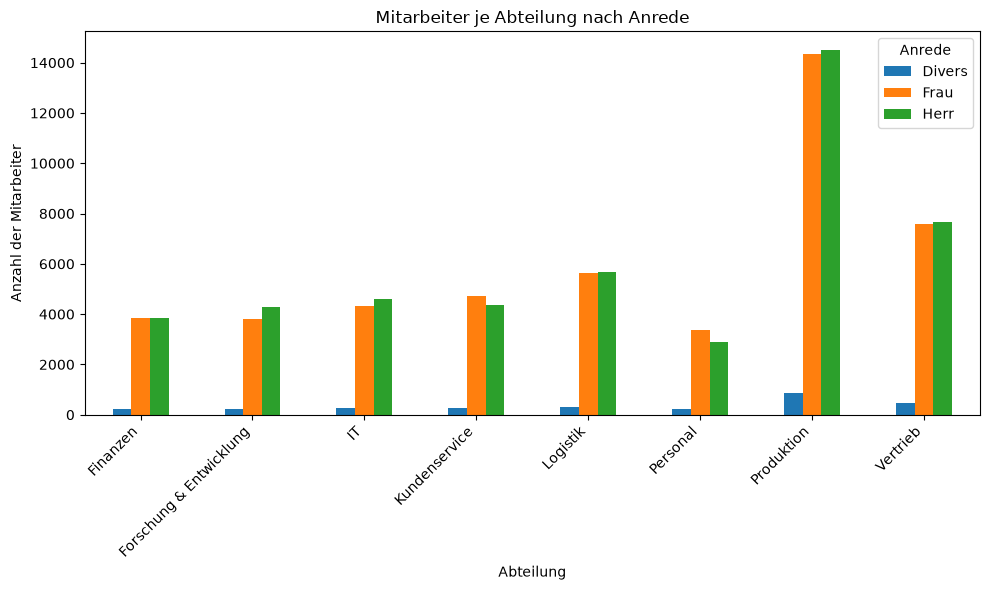

In [419]:
abt_tabelle = pd.crosstab(df["Abteilung"], df["Anrede"])

print(abt_tabelle)

abt_tabelle.plot(kind="bar", figsize=(10, 6))
plt.title("Mitarbeiter je Abteilung nach Anrede")
plt.xlabel("Abteilung")
plt.ylabel("Anzahl der Mitarbeiter")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [420]:
def kennzahlen(s):
    return pd.Series({
        "Mittelwert": s.mean(),
        "Empirische Varianz": s.var(ddof=1),
        "Empirische Std.abw.": s.std(ddof=1),
        "Median": s.median(),
        "Spannweite": s.max() - s.min()
    })

def kennzahlen_tabelle(spalte):
    gruppen = {"Gesamt": df[spalte]}
    for anrede in ["Herr", "Frau", "Divers"]:
        gruppen[anrede] = df.loc[df["Anrede"] == anrede, spalte]
    return pd.DataFrame({k: kennzahlen(v) for k, v in gruppen.items()}).round(4)

pd.options.display.float_format = "{:.4f}".format

print("Kennzahlen: Alter (Jahre)")
display(kennzahlen_tabelle("Alter"))

print("Kennzahlen: Jahresgehalt (€)")
display(kennzahlen_tabelle("Jahresgehalt"))

Kennzahlen: Alter (Jahre)


,Gesamt,Herr,Frau,Divers
Mittelwert,43.9958,43.9962,43.9825,44.2083
Empirische Varianz,200.1649,200.3500,200.1098,198.0956
Empirische Std.abw.,14.1480,14.1545,14.1460,14.0746
Median,44.0000,44.0000,44.0000,44.0000
Spannweite,48.0000,48.0000,48.0000,48.0000


Kennzahlen: Jahresgehalt (€)


,Gesamt,Herr,Frau,Divers
Mittelwert,49633.5581,50258.4472,48969.4555,50233.6682
Empirische Varianz,83698555.0513,85577204.9108,80736744.3885,87378721.7018
Empirische Std.abw.,9148.6914,9250.7948,8985.3628,9347.6586
Median,49051.1400,49716.7700,48384.4000,49309.4500
Spannweite,49983.2625,49908.7625,49983.2625,46342.2825


In [421]:

from scipy.stats import pearsonr, spearmanr

pearson, p_pearson = pearsonr(
    df["Alter"], df["Jahresgehalt"]
)

spearman, p_spearman = spearmanr(
    df["Alter"], df["Jahresgehalt"]
)

print(f"Pearson-Korrelation: {pearson:.4f}")
print(f"Spearman-Korrelation: {spearman:.4f}")


Pearson-Korrelation: 0.6206
Spearman-Korrelation: 0.6343


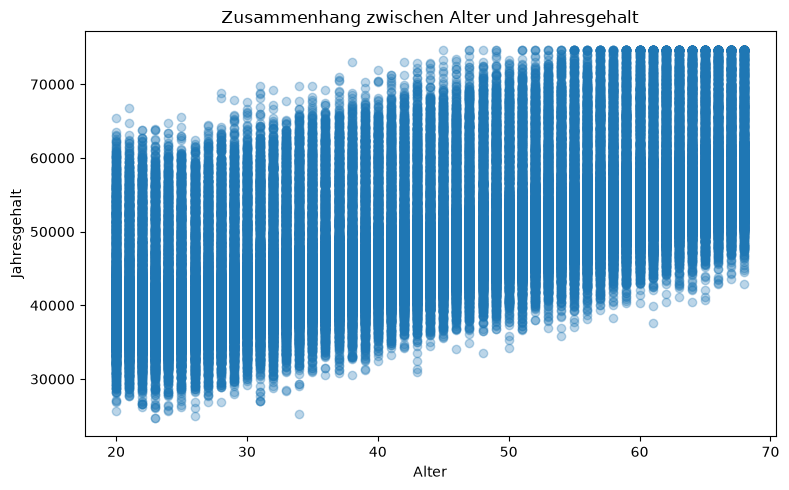

In [422]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Alter"],
    df["Jahresgehalt"],
    alpha=0.3
)
plt.xlabel("Alter")
plt.ylabel("Jahresgehalt")
plt.title("Zusammenhang zwischen Alter und Jahresgehalt")
plt.tight_layout()
plt.show()


### Fazit zur Zusammenhangsanalyse f)

Bei der Auswertung zeigt sich, dass die beiden Korrelationskoeffizienten sehr nah beieinanderliegen. Der Pearson-Koeffizient beträgt 0,6205 und der Spearman-Koeffizient 0,6342. Beide weisen auf einen deutlichen positiven Zusammenhang zwischen Alter und Jahresgehalt hin.

Das bedeutet, dass ältere Mitarbeitende tendenziell mehr verdienen. Da sich die beiden Koeffizienten nur geringfügig unterscheiden, gibt es keinen Hinweis auf einen starken Unterschied zwischen dem linearen und dem monotonen Zusammenhang. Ob der Zusammenhang tatsächlich annähernd linear ist, lässt sich anhand des Streudiagramms genauer beurteilen.

Insgesamt besteht ein deutlicher positiver Zusammenhang zwischen Alter und Jahresgehalt. Daraus lässt sich jedoch nicht schließen, dass ein höheres Alter direkt die Ursache für ein höheres Gehalt ist.

In [423]:
kennzahlen = ["Alter", "Jahresgehalt"]

def spannweite(x):
    return x.max() - x.min()

funktionen = ["mean", "var", "std", "median", spannweite]

# Insgesamt
print("Gesamt:")
display(df[kennzahlen].agg(funktionen).round(4))

# Getrennt nach Anrede
print("Nach Anrede:")
ergebnis = df.groupby("Anrede")[kennzahlen].agg(funktionen).round(4)

display(ergebnis)

Gesamt:


,Alter,Jahresgehalt
mean,43.9958,49633.5581
var,200.1649,83698555.0513
std,14.1480,9148.6914
median,44.0000,49051.1400
spannweite,48.0000,49983.2625


Nach Anrede:


Alter                                     Jahresgehalt                \
          mean      var     std  median spannweite         mean           var   
Anrede                                                                          
Divers 44.2083 198.0956 14.0746 44.0000         48   50233.6682 87378721.7018   
Frau   43.9825 200.1098 14.1460 44.0000         48   48969.4555 80736744.3885   
Herr   43.9962 200.3500 14.1545 44.0000         48   50258.4472 85577204.9108   

                                        
             std     median spannweite  
Anrede                                  
Divers 9347.6586 49309.4500 46342.2825  
Frau   8985.3628 48384.4000 49983.2625  
Herr   9250.7948 49716.7700 49908.7625

### Fazit – Diskussion der Gehaltsunterschiede g)

Beim Vergleich der Kennzahlen fällt auf, dass es Unterschiede zwischen den Jahresgehältern der verschiedenen Anreden gibt. Das durchschnittliche Jahresgehalt liegt bei „Herr“ bei 50.258,45 €, bei „Divers“ bei 50.233,67 € und bei „Frau“ bei 48.969,46 €. Auch beim Median liegt das Jahresgehalt bei „Herr“ mit 49.716,77 € über dem Wert bei „Frau“ mit 48.384,40 €.

Daraus lässt sich vermuten, dass Mitarbeitende mit der Anrede „Herr“ in diesem Datensatz tendenziell mehr verdienen als Mitarbeitende mit der Anrede „Frau“. Der Unterschied im durchschnittlichen Jahresgehalt beträgt ungefähr 1.289 € pro Jahr.

Allerdings beweist dies noch nicht, dass die Anrede selbst der Grund dafür ist. Auch Faktoren wie Abteilung, Alter oder Führungsposition könnten die Unterschiede beeinflussen. Ob der beobachtete Gehaltsunterschied statistisch signifikant ist, wird in Teil 5 überprüft.